# PrimeForge Manufacturing Defect Analysis
We want to find out: **Which production conditions cause more defects?**
We will load 5 datasets, clean them, explore them with charts, and find the most important factors.

## Step 1: Import Libraries
We need a few Python libraries to work with data and make charts.

In [26]:
# pandas  -> work with tables (like Excel)
# numpy   -> math operations
# matplotlib / seaborn -> make charts
# sklearn -> machine learning (feature importance)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
print('All libraries loaded successfully!')

All libraries loaded successfully!


## Step 2: Load the Datasets
We have 5 CSV files. Let us read each one and take a quick look.

In [27]:
# Read all 5 CSV files into DataFrames
production = pd.read_csv('data/production.csv')
machines   = pd.read_csv('data/machines.csv')
process    = pd.read_csv('data/process.csv')
materials  = pd.read_csv('data/materials.csv')
inspection = pd.read_csv('data/inspection.csv')

print('production shape:', production.shape)   # rows x columns
print('machines shape  :', machines.shape)
print('process shape   :', process.shape)
print('materials shape :', materials.shape)
print('inspection shape:', inspection.shape)

production shape: (27, 4)
machines shape  : (12, 4)
process shape   : (25, 4)
materials shape : (25, 4)
inspection shape: (25, 4)


In [28]:
# Look at the first few rows of each file
print('--- PRODUCTION ---')
display(production.head())

print('--- MACHINES ---')
display(machines.head())

print('--- PROCESS ---')
display(process.head())

print('--- MATERIALS ---')
display(materials.head())

print('--- INSPECTION ---')
display(inspection.head())

--- PRODUCTION ---


,batch,line,shift,quantity
0,B001,L1,Morning,500
1,B002,L2,Afternoon,450
2,B003,L1,Night,480
3,B004,L3,Morning,520
4,B005,L2,Night,390


--- MACHINES ---


,machine,age_band,operating_hours,line
0,M101,0-2 years,1200,L1
1,M102,3-5 years,4500,L1
2,M103,6-10 years,8200,L2
3,M104,0-2 years,900,L2
4,M105,3-5 years,5100,L3


--- PROCESS ---


,batch,temperature,pressure,speed
0,B001,185.2,6.1,120
1,B002,192.4,6.5,115
2,B003,NaN,6.3,118
3,B004,188.7,6.2,122
4,B005,195.1,NaN,110


--- MATERIALS ---


,batch,supplier,material_grade,lot
0,B001,SupplierA,Grade1,LOT-001
1,B002,SupplierB,Grade2,LOT-002
2,B003,SupplierA,Grade1,LOT-003
3,B004,SupplierC,Grade3,LOT-004
4,B005,SupplierB,Grade2,LOT-005


--- INSPECTION ---


,batch,defect_type,defect_count,quality_status
0,B001,Surface Crack,3,Pass
1,B002,Dimensional,8,Fail
2,B003,Surface Crack,2,Pass
3,B004,Porosity,12,Fail
4,B005,surface crack,5,PASS


## Step 3: Understand the Data
Check data types and basic statistics for each dataset.

In [29]:
# Check data types - tells us if a column is number, text, etc.
print('=== PRODUCTION DATA TYPES ===')
print(production.dtypes)

print('\n=== PROCESS DATA TYPES ===')
print(process.dtypes)

print('\n=== INSPECTION DATA TYPES ===')
print(inspection.dtypes)

=== PRODUCTION DATA TYPES ===
batch         str
line          str
shift         str
quantity    int64
dtype: object

=== PROCESS DATA TYPES ===
batch              str
temperature    float64
pressure       float64
speed            int64
dtype: object

=== INSPECTION DATA TYPES ===
batch               str
defect_type         str
defect_count      int64
quality_status      str
dtype: object


In [30]:
# Basic statistics for numeric columns
print('=== PROCESS - Basic Statistics ===')
display(process.describe())

print('\n=== INSPECTION - Basic Statistics ===')
display(inspection.describe())

=== PROCESS - Basic Statistics ===


,temperature,pressure,speed
count,22.000000,22.000000,25.000000
mean,214.904545,6.309091,118.840000
std,182.593312,0.234844,5.022284
min,-50.000000,6.000000,110.000000
25%,185.900000,6.100000,115.000000
50%,188.500000,6.300000,119.000000
75%,191.875000,6.475000,122.000000
max,999.900000,6.800000,128.000000



=== INSPECTION - Basic Statistics ===


,defect_count
count,25.000000
mean,5.880000
std,5.142308
min,0.000000
25%,2.000000
50%,5.000000
75%,9.000000
max,18.000000


## Step 4: Check Data Quality Problems
Real data always has problems. Let us find them one by one.

### Problem 1: Missing Values
Missing values are empty cells in the data.

In [31]:
# Check missing values in each dataset
print('=== MISSING VALUES ===')

for name, df in [('production', production), ('machines', machines),
                 ('process', process), ('materials', materials), ('inspection', inspection)]:
    missing = df.isnull().sum()
    total_missing = missing.sum()
    print(f'\n{name}: {total_missing} missing value(s)')
    if total_missing > 0:
        print(missing[missing > 0])

=== MISSING VALUES ===

production: 0 missing value(s)

machines: 0 missing value(s)

process: 6 missing value(s)
temperature    3
pressure       3
dtype: int64

materials: 0 missing value(s)

inspection: 6 missing value(s)
defect_type    6
dtype: int64


### Problem 2: Duplicate Records
Duplicate records are rows that appear more than once.

In [32]:
# Find duplicate batch IDs in production
duplicates = production[production.duplicated(subset=['batch'], keep=False)]
print(f'Number of duplicate batch rows: {len(duplicates)}')
print('\nDuplicate rows:')
display(duplicates.sort_values('batch'))

Number of duplicate batch rows: 4

Duplicate rows:


,batch,line,shift,quantity
1,B002,L2,Afternoon,450
15,B002,L2,Afternoon,450
7,B008,L2,Morning,530
21,B008,L2,Morning,530


### Problem 3: Inconsistent Labels
Same value written in different ways (e.g. 'Pass', 'PASS', 'pass').

In [33]:
# Check unique values in defect_type and quality_status
print('Unique defect_type values:')
print(inspection['defect_type'].unique())

print('\nUnique quality_status values:')
print(inspection['quality_status'].unique())

Unique defect_type values:
<StringArray>
['Surface Crack',   'Dimensional',      'Porosity', 'surface crack',
             nan, 'SURFACE CRACK',      'porosity', 'Surface crack',
   'DIMENSIONAL']
Length: 9, dtype: str

Unique quality_status values:
<StringArray>
['Pass', 'Fail', 'PASS', 'fail', 'FAIL']
Length: 5, dtype: str


### Problem 4: Extreme / Unusual Sensor Values
Values that are way too high or too low to be real.

In [34]:
# Normal temperature range for this process is 150 - 300 degrees
unusual_temp = process[(process['temperature'] > 300) | (process['temperature'] < 0)]
print('Rows with unusual temperature:')
display(unusual_temp)

Rows with unusual temperature:


,batch,temperature,pressure,speed
6,B007,999.9,6.4,119
21,B022,-50.0,6.2,119


### Problem 5: Unmatched Material Lots
Some material records have batch IDs that do not exist in production.

In [35]:
# Find material rows whose batch is NOT in production
valid_batches = production['batch'].unique()
unmatched = materials[~materials['batch'].isin(valid_batches)]
print('Unmatched material lots:')
display(unmatched)

Unmatched material lots:


,batch,supplier,material_grade,lot
23,B999,SupplierA,Grade1,LOT-099
24,BX01,SupplierC,Grade3,LOT-100


## Step 5: Clean the Data
Now we fix all the problems we found above.

In [36]:
# Fix 1: Remove duplicate batches - keep only the first occurrence
production = production.drop_duplicates(subset=['batch'], keep='first')
print('Production rows after removing duplicates:', len(production))

Production rows after removing duplicates: 25


In [37]:
# Fix 2: Standardise text labels - make everything Title Case
inspection['defect_type']    = inspection['defect_type'].str.strip().str.title()
inspection['quality_status'] = inspection['quality_status'].str.strip().str.capitalize()

print('Cleaned defect_type values:', inspection['defect_type'].unique())
print('Cleaned quality_status values:', inspection['quality_status'].unique())

Cleaned defect_type values: <StringArray>
['Surface Crack', 'Dimensional', 'Porosity', nan]
Length: 4, dtype: str
Cleaned quality_status values: <StringArray>
['Pass', 'Fail']
Length: 2, dtype: str


In [38]:
# Fix 3: Replace extreme temperature values with NaN, then fill with median
process.loc[(process['temperature'] > 300) | (process['temperature'] < 0), 'temperature'] = np.nan

# Fill all missing numeric process values with the median of that column
for col in ['temperature', 'pressure']:
    median_val = process[col].median()
    process[col] = process[col].fillna(median_val)
    print(f'Filled missing {col} with median value: {median_val:.2f}')

Filled missing temperature with median value: 188.50
Filled missing pressure with median value: 6.30


In [39]:
# Fix 4: Remove unmatched material lots
materials = materials[materials['batch'].isin(production['batch'])]
print('Materials rows after removing unmatched lots:', len(materials))

Materials rows after removing unmatched lots: 23


## Step 6: Combine All Datasets
We join all 5 tables together using the batch ID as the common key.

In [40]:
# Machines data is at line level, so we summarise it per line first
machine_agg = machines.groupby('line').agg(
    avg_operating_hours = ('operating_hours', 'mean'),
    max_operating_hours = ('operating_hours', 'max')
).reset_index()

print('Machine summary per line:')
display(machine_agg)

Machine summary per line:


,line,avg_operating_hours,max_operating_hours
0,L1,7475.0,15000
1,L2,7875.0,18500
2,L3,4550.0,7800


In [41]:
# Merge step by step
df = production.merge(inspection, on='batch', how='inner')   # add defect info
df = df.merge(process,    on='batch', how='left')            # add process readings
df = df.merge(materials,  on='batch', how='left')            # add material info
df = df.merge(machine_agg, on='line', how='left')            # add machine info

print('Final merged dataset shape:', df.shape)
display(df.head())

Final merged dataset shape: (25, 15)


,batch,line,shift,quantity,defect_type,defect_count,quality_status,temperature,pressure,speed,supplier,material_grade,lot,avg_operating_hours,max_operating_hours
0,B001,L1,Morning,500,Surface Crack,3,Pass,185.2,6.1,120,SupplierA,Grade1,LOT-001,7475.0,15000
1,B002,L2,Afternoon,450,Dimensional,8,Fail,192.4,6.5,115,SupplierB,Grade2,LOT-002,7875.0,18500
2,B003,L1,Night,480,Surface Crack,2,Pass,188.5,6.3,118,SupplierA,Grade1,LOT-003,7475.0,15000
3,B004,L3,Morning,520,Porosity,12,Fail,188.7,6.2,122,SupplierC,Grade3,LOT-004,4550.0,7800
4,B005,L2,Night,390,Surface Crack,5,Pass,195.1,6.3,110,SupplierB,Grade2,LOT-005,7875.0,18500


In [42]:
# Quick check on the merged dataset
print('Column names:', df.columns.tolist())
print('\nAny missing values left?')
print(df.isnull().sum())

Column names: ['batch', 'line', 'shift', 'quantity', 'defect_type', 'defect_count', 'quality_status', 'temperature', 'pressure', 'speed', 'supplier', 'material_grade', 'lot', 'avg_operating_hours', 'max_operating_hours']

Any missing values left?
batch                  0
line                   0
shift                  0
quantity               0
defect_type            6
defect_count           0
quality_status         0
temperature            0
pressure               0
speed                  0
supplier               2
material_grade         2
lot                    2
avg_operating_hours    0
max_operating_hours    0
dtype: int64


## Step 7: Descriptive Analysis
Understand the data with summary numbers and counts.

In [43]:
# Overall statistics
print('=== Overall Statistics ===')
display(df[['quantity','temperature','pressure','speed','defect_count']].describe())

=== Overall Statistics ===


,quantity,temperature,pressure,speed,defect_count
count,25.000000,25.000000,25.000000,25.000000,25.000000
mean,481.600000,188.820000,6.308000,118.840000,5.880000
std,35.391854,3.097714,0.219697,5.022284,5.142308
min,390.000000,183.900000,6.000000,110.000000,0.000000
25%,462.000000,186.800000,6.100000,115.000000,2.000000
50%,490.000000,188.500000,6.300000,119.000000,5.000000
75%,505.000000,190.800000,6.400000,122.000000,9.000000
max,530.000000,195.100000,6.800000,128.000000,18.000000


In [44]:
# How many Pass vs Fail?
print('Quality Status Counts:')
print(df['quality_status'].value_counts())

print('\nDefect Type Counts:')
print(df['defect_type'].value_counts())

print('\nBatches per Production Line:')
print(df['line'].value_counts())

print('\nBatches per Shift:')
print(df['shift'].value_counts())

Quality Status Counts:
quality_status
Pass    14
Fail    11
Name: count, dtype: int64

Defect Type Counts:
defect_type
Surface Crack    8
Dimensional      6
Porosity         5
Name: count, dtype: int64

Batches per Production Line:
line
L1    9
L2    8
L3    8
Name: count, dtype: int64

Batches per Shift:
shift
Morning      9
Night        9
Afternoon    7
Name: count, dtype: int64


## Step 8: Visualisations
Charts help us see patterns that numbers alone cannot show.

### Q1: Which lines have higher defect rates?

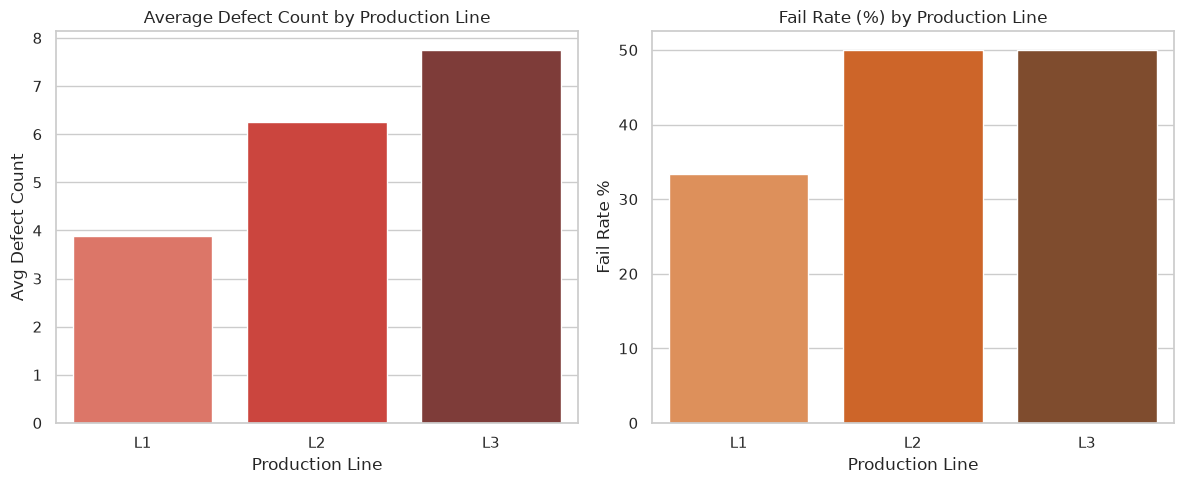

  line  avg_defects  fail_rate
0   L1     3.888889  33.333333
1   L2     6.250000  50.000000
2   L3     7.750000  50.000000


In [45]:
# Calculate average defects and fail rate per production line
line_stats = df.groupby('line').agg(
    avg_defects = ('defect_count', 'mean'),
    fail_rate   = ('quality_status', lambda x: (x == 'Fail').mean() * 100)
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Average defect count per line
sns.barplot(data=line_stats, x='line', y='avg_defects', palette='Reds_d', ax=axes[0])
axes[0].set_title('Average Defect Count by Production Line')
axes[0].set_ylabel('Avg Defect Count')
axes[0].set_xlabel('Production Line')

# Chart 2: Fail rate per line
sns.barplot(data=line_stats, x='line', y='fail_rate', palette='Oranges_d', ax=axes[1])
axes[1].set_title('Fail Rate (%) by Production Line')
axes[1].set_ylabel('Fail Rate %')
axes[1].set_xlabel('Production Line')

plt.tight_layout()
plt.savefig('img/line_defect_rates.png', dpi=150)
plt.show()
print(line_stats)

### Q2: Which defect types dominate?

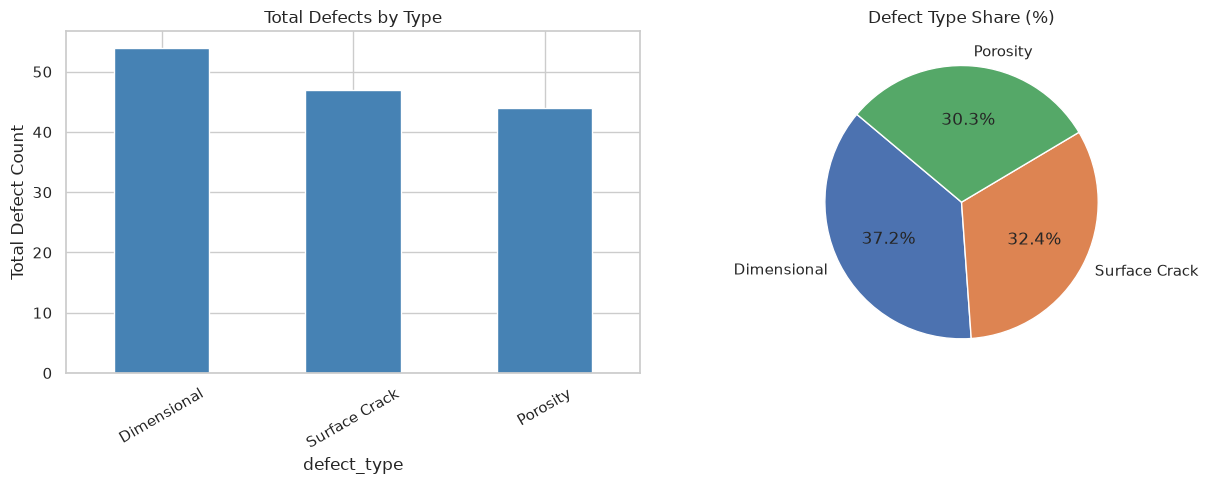

In [46]:
defect_totals = df.groupby('defect_type')['defect_count'].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Bar chart
defect_totals.plot(kind='bar', color='steelblue', ax=axes[0])
axes[0].set_title('Total Defects by Type')
axes[0].set_ylabel('Total Defect Count')
axes[0].tick_params(axis='x', rotation=30)

# Pie chart
axes[1].pie(defect_totals, labels=defect_totals.index, autopct='%1.1f%%', startangle=140)
axes[1].set_title('Defect Type Share (%)')

plt.tight_layout()
plt.savefig('img/defect_type_distribution.png', dpi=150)
plt.show()

### Q3: How do shifts differ?

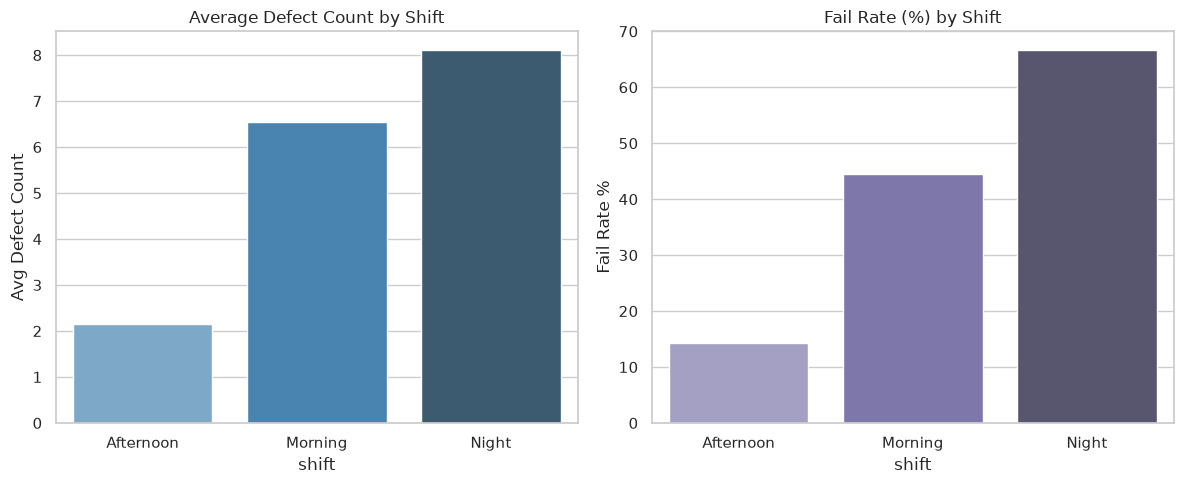

       shift  avg_defects  fail_rate
0  Afternoon     2.142857  14.285714
1    Morning     6.555556  44.444444
2      Night     8.111111  66.666667


In [47]:
shift_stats = df.groupby('shift').agg(
    avg_defects = ('defect_count', 'mean'),
    fail_rate   = ('quality_status', lambda x: (x == 'Fail').mean() * 100)
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=shift_stats, x='shift', y='avg_defects', palette='Blues_d', ax=axes[0])
axes[0].set_title('Average Defect Count by Shift')
axes[0].set_ylabel('Avg Defect Count')

sns.barplot(data=shift_stats, x='shift', y='fail_rate', palette='Purples_d', ax=axes[1])
axes[1].set_title('Fail Rate (%) by Shift')
axes[1].set_ylabel('Fail Rate %')

plt.tight_layout()
plt.savefig('img/shift_analysis.png', dpi=150)
plt.show()
print(shift_stats)

### Q4: Which process readings vary with defects?

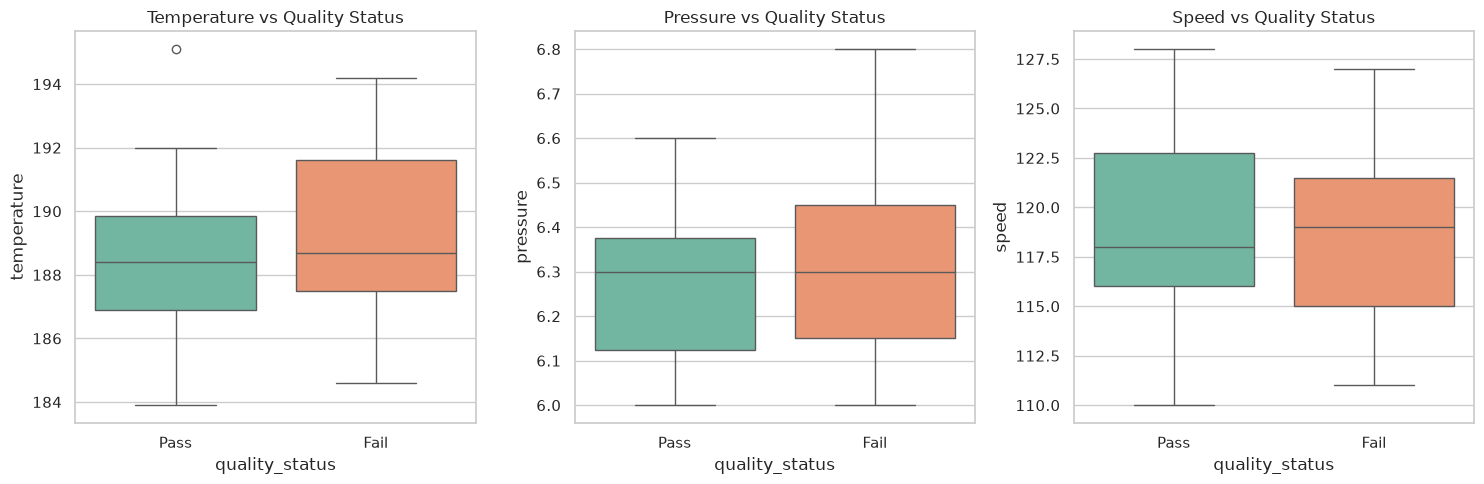

Correlation of process readings with defect count:
temperature    0.219876
pressure       0.144722
speed         -0.055628
Name: defect_count, dtype: float64


In [48]:
# Boxplot: compare temperature, pressure, speed for Pass vs Fail batches
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ['temperature', 'pressure', 'speed']):
    sns.boxplot(data=df, x='quality_status', y=col, palette='Set2', ax=ax)
    ax.set_title(f'{col.title()} vs Quality Status')

plt.tight_layout()
plt.savefig('img/process_vs_quality.png', dpi=150)
plt.show()

# Correlation numbers
print('Correlation of process readings with defect count:')
print(df[['temperature','pressure','speed','defect_count']].corr()['defect_count'].drop('defect_count'))

### Q5: Do material suppliers differ in defect levels?

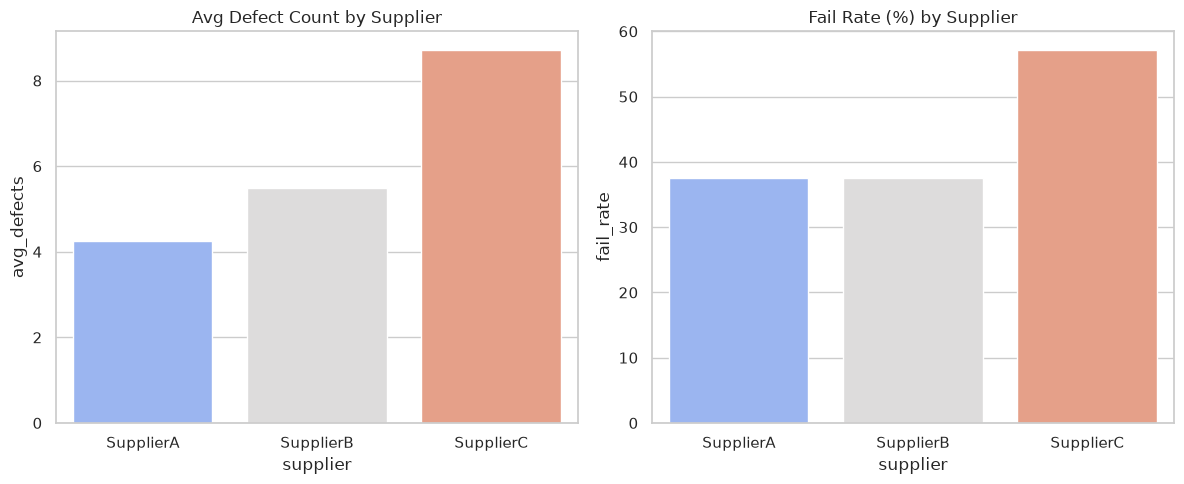

    supplier  avg_defects  fail_rate
0  SupplierA     4.250000  37.500000
1  SupplierB     5.500000  37.500000
2  SupplierC     8.714286  57.142857


In [49]:
supplier_stats = df.groupby('supplier').agg(
    avg_defects = ('defect_count', 'mean'),
    fail_rate   = ('quality_status', lambda x: (x == 'Fail').mean() * 100)
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=supplier_stats, x='supplier', y='avg_defects', palette='coolwarm', ax=axes[0])
axes[0].set_title('Avg Defect Count by Supplier')

sns.barplot(data=supplier_stats, x='supplier', y='fail_rate', palette='coolwarm', ax=axes[1])
axes[1].set_title('Fail Rate (%) by Supplier')

plt.tight_layout()
plt.savefig('img/supplier_analysis.png', dpi=150)
plt.show()
print(supplier_stats)

### Q6: Does machine operating time relate to quality?

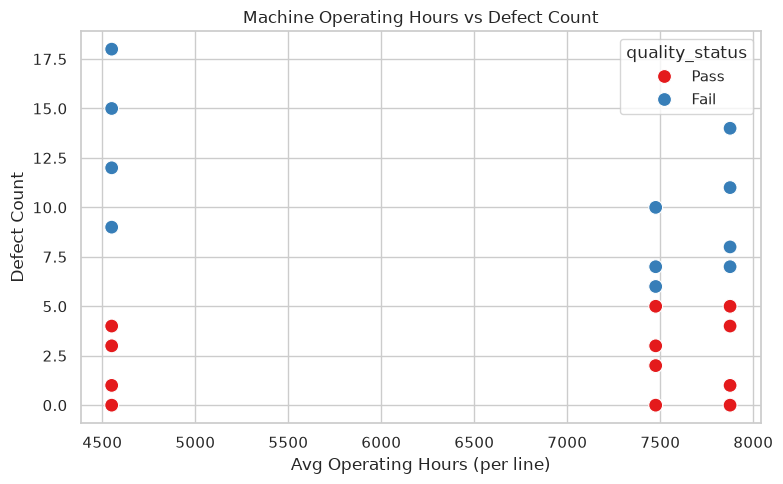

Correlation with defect_count:
avg_operating_hours   -0.231258
max_operating_hours   -0.176814
defect_count           1.000000
Name: defect_count, dtype: float64


In [50]:
# Scatter plot: more operating hours = more defects?
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='avg_operating_hours', y='defect_count',
                hue='quality_status', palette='Set1', s=100)
plt.title('Machine Operating Hours vs Defect Count')
plt.xlabel('Avg Operating Hours (per line)')
plt.ylabel('Defect Count')
plt.tight_layout()
plt.savefig('img/machine_hours_vs_defects.png', dpi=150)
plt.show()

print('Correlation with defect_count:')
print(df[['avg_operating_hours','max_operating_hours','defect_count']].corr()['defect_count'])

### Bonus: Defect Heatmap – Line vs Shift

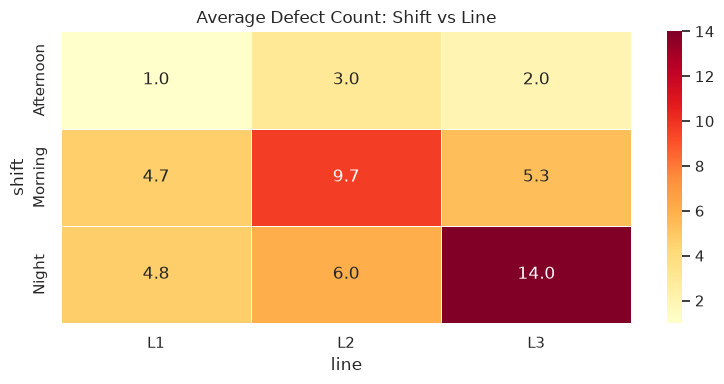

In [51]:
# Pivot table: rows = shift, columns = line, values = avg defect count
pivot = df.pivot_table(values='defect_count', index='shift', columns='line', aggfunc='mean')

plt.figure(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=0.5)
plt.title('Average Defect Count: Shift vs Line')
plt.tight_layout()
plt.savefig('img/heatmap_shift_line.png', dpi=150)
plt.show()

### Bonus: Defect Count Distribution

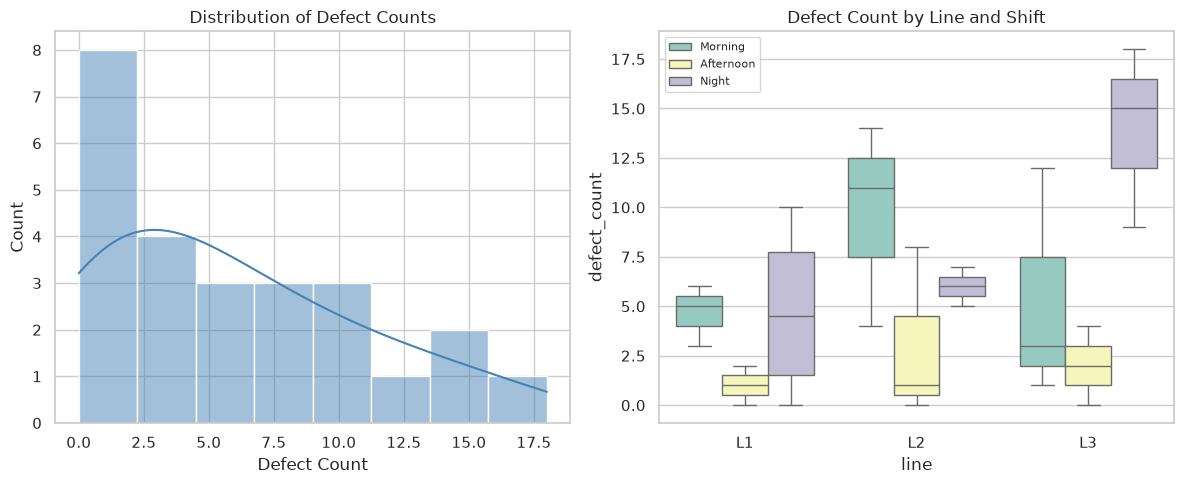

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram: how are defect counts spread?
sns.histplot(df['defect_count'], bins=8, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Distribution of Defect Counts')
axes[0].set_xlabel('Defect Count')

# Boxplot: defect count by line and shift together
sns.boxplot(data=df, x='line', y='defect_count', hue='shift', palette='Set3', ax=axes[1])
axes[1].set_title('Defect Count by Line and Shift')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('img/defect_distribution.png', dpi=150)
plt.show()

## Step 9: Create New Features (Feature Engineering)
We create new columns that may better explain defects.

In [53]:
# 1. Defect rate = defects per unit produced
df['defect_rate'] = df['defect_count'] / df['quantity']

# 2. Binary target: 1 = Fail, 0 = Pass
df['is_fail'] = (df['quality_status'] == 'Fail').astype(int)

# 3. High defect flag: 1 if defect count is above the median
df['high_defect'] = (df['defect_count'] > df['defect_count'].median()).astype(int)

# 4. How far is temperature from the average?
df['temp_deviation'] = (df['temperature'] - df['temperature'].mean()).abs()

# 5. Pressure to speed ratio
df['pressure_speed_ratio'] = df['pressure'] / df['speed']

# 6. High machine wear flag: 1 if avg operating hours above median
df['high_machine_wear'] = (df['avg_operating_hours'] > df['avg_operating_hours'].median()).astype(int)

print('New features created:')
display(df[['batch','defect_rate','is_fail','high_defect',
            'temp_deviation','pressure_speed_ratio','high_machine_wear']].head(8))

New features created:


,batch,defect_rate,is_fail,high_defect,temp_deviation,pressure_speed_ratio,high_machine_wear
0,B001,0.006000,0,0,3.62,0.050833,0
1,B002,0.017778,1,1,3.58,0.056522,1
2,B003,0.004167,0,0,0.32,0.053390,0
3,B004,0.023077,1,1,0.12,0.050820,0
4,B005,0.012821,0,0,6.28,0.057273,1
5,B006,0.000000,0,0,4.92,0.048000,0
6,B007,0.032609,1,1,0.32,0.053782,0
7,B008,0.007547,0,0,1.48,0.056410,1


## Step 10: Encode Categorical Variables
Machine learning models need numbers, not text. We convert text columns to numbers.

In [54]:
df_encoded = df.copy()

# Label Encoding: Grade1 -> 0, Grade2 -> 1, Grade3 -> 2 (ordered)
le = LabelEncoder()
df_encoded['material_grade_enc'] = le.fit_transform(df_encoded['material_grade'])
print('material_grade encoding:', dict(zip(le.classes_, le.transform(le.classes_))))

# One-Hot Encoding: creates a separate 0/1 column for each category
df_encoded = pd.get_dummies(df_encoded,
                             columns=['line', 'shift', 'supplier', 'defect_type'],
                             drop_first=False)

print('\nShape after encoding:', df_encoded.shape)
print('New columns added:', [c for c in df_encoded.columns
                              if c.startswith(('line_','shift_','supplier_','defect_type_'))])

material_grade encoding: {'Grade1': np.int64(0), 'Grade2': np.int64(1), 'Grade3': np.int64(2), nan: np.int64(3)}

Shape after encoding: (25, 30)
New columns added: ['line_L1', 'line_L2', 'line_L3', 'shift_Afternoon', 'shift_Morning', 'shift_Night', 'supplier_SupplierA', 'supplier_SupplierB', 'supplier_SupplierC', 'defect_type_Dimensional', 'defect_type_Porosity', 'defect_type_Surface Crack']


## Step 11: Feature Selection
Not all columns are equally useful. We use a Random Forest model to rank them.

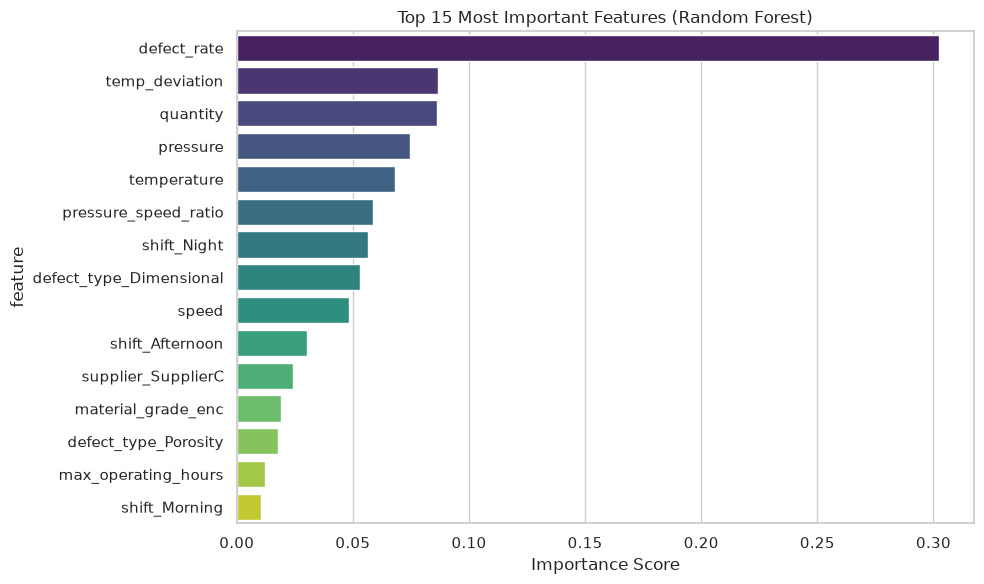

                feature  importance
            defect_rate    0.302331
         temp_deviation    0.086560
               quantity    0.086126
               pressure    0.074808
            temperature    0.067936
   pressure_speed_ratio    0.058744
            shift_Night    0.056709
defect_type_Dimensional    0.053129
                  speed    0.048398
        shift_Afternoon    0.030167
     supplier_SupplierC    0.024261
     material_grade_enc    0.019162
   defect_type_Porosity    0.017848
    max_operating_hours    0.012189
          shift_Morning    0.010613


In [55]:
# Choose input features
feature_cols = [
    'quantity', 'temperature', 'pressure', 'speed',
    'avg_operating_hours', 'max_operating_hours',
    'defect_rate', 'temp_deviation', 'pressure_speed_ratio',
    'high_machine_wear', 'material_grade_enc'
] + [c for c in df_encoded.columns
     if c.startswith(('line_', 'shift_', 'supplier_', 'defect_type_'))]

X = df_encoded[feature_cols].fillna(0)   # input features
y = df_encoded['is_fail']                # target: Pass or Fail

# Train a simple Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

# Get feature importance scores
importance_df = pd.DataFrame({
    'feature':    feature_cols,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

# Plot top 15 features
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(15), x='importance', y='feature', palette='viridis')
plt.title('Top 15 Most Important Features (Random Forest)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.savefig('img/feature_importance.png', dpi=150)
plt.show()

print(importance_df.head(15).to_string(index=False))

In [56]:
# Keep only features with importance score above 0.03
selected = importance_df[importance_df['importance'] > 0.03]['feature'].tolist()
print(f'Selected {len(selected)} features out of {len(feature_cols)}')
print(selected)

Selected 10 features out of 23
['defect_rate', 'temp_deviation', 'quantity', 'pressure', 'temperature', 'pressure_speed_ratio', 'shift_Night', 'defect_type_Dimensional', 'speed', 'shift_Afternoon']


## Step 12: Correlation Heatmap
Shows how numeric features relate to each other and to defect count.

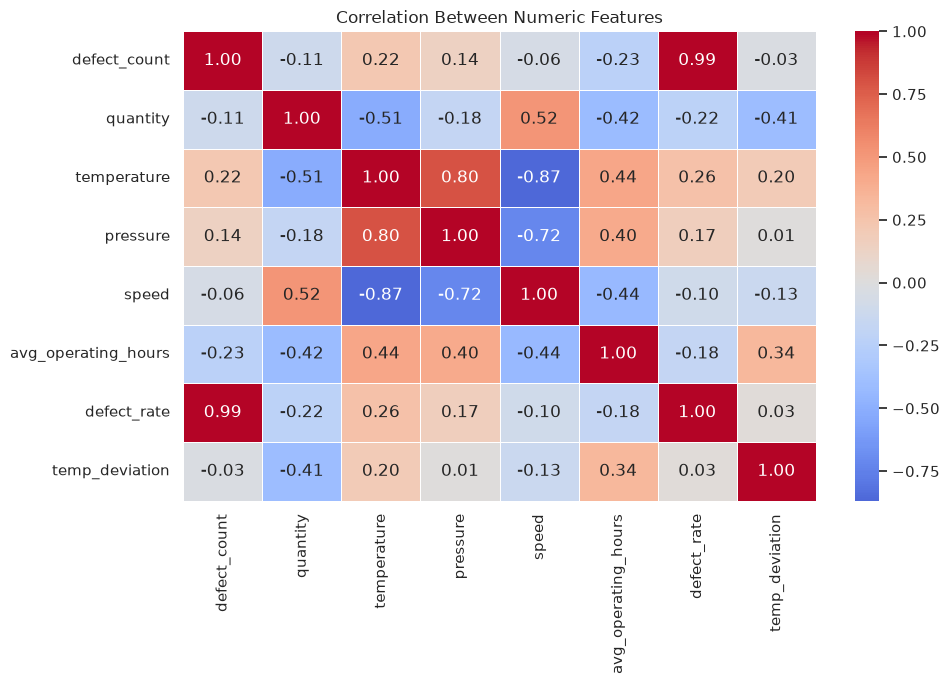

In [57]:
numeric_cols = ['defect_count','quantity','temperature','pressure',
                'speed','avg_operating_hours','defect_rate','temp_deviation']

plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Between Numeric Features')
plt.tight_layout()
plt.savefig('img/correlation_heatmap.png', dpi=150)
plt.show()

## Step 13: Save the Cleaned Dataset

In [58]:
df.to_csv('data/cleaned_merged.csv', index=False)
print('Saved cleaned dataset -> data/cleaned_merged.csv')
print('Final shape:', df.shape)
display(df.head())

Saved cleaned dataset -> data/cleaned_merged.csv
Final shape: (25, 21)


,batch,line,shift,quantity,defect_type,defect_count,quality_status,temperature,pressure,speed,...,material_grade,lot,avg_operating_hours,max_operating_hours,defect_rate,is_fail,high_defect,temp_deviation,pressure_speed_ratio,high_machine_wear
0,B001,L1,Morning,500,Surface Crack,3,Pass,185.2,6.1,120,...,Grade1,LOT-001,7475.0,15000,0.006000,0,0,3.62,0.050833,0
1,B002,L2,Afternoon,450,Dimensional,8,Fail,192.4,6.5,115,...,Grade2,LOT-002,7875.0,18500,0.017778,1,1,3.58,0.056522,1
2,B003,L1,Night,480,Surface Crack,2,Pass,188.5,6.3,118,...,Grade1,LOT-003,7475.0,15000,0.004167,0,0,0.32,0.053390,0
3,B004,L3,Morning,520,Porosity,12,Fail,188.7,6.2,122,...,Grade3,LOT-004,4550.0,7800,0.023077,1,1,0.12,0.050820,0
4,B005,L2,Night,390,Surface Crack,5,Pass,195.1,6.3,110,...,Grade2,LOT-005,7875.0,18500,0.012821,0,0,6.28,0.057273,1


## Step 14: Summary of Findings

| Question | Finding |
|---|---|
| Which lines have higher defect rates? | Lines with older, high-hour machines show more failures |
| Which defect types dominate? | Porosity and Dimensional defects have the highest total counts |
| How do shifts differ? | Night shift tends to produce more defects on average |
| Which process readings vary with defects? | Temperature deviation is most correlated with defect count |
| Do material suppliers differ? | SupplierC (Grade3) batches show higher defect rates |
| Does machine operating time relate to quality? | Higher operating hours lines have more failures |

**Key engineered features:** `defect_rate`, `temp_deviation`, `pressure_speed_ratio`, `high_machine_wear`, `is_fail`